In [1]:
import sys
import yaml
import numpy as np
import pandas as pd
from pathlib import Path

sys.path.append("../..")
from src.solvers.sqbm import solve_wflo_sqbm
from src.solvers.utils import save_benchmark_layout
from src.qubo_windfarm_layout.evaluation import load_layout_coordinates, layouts_folder_to_df
from src.qubo_windfarm_layout.visualization import plot_refinement, plot_selected_layout
from src.qubo_windfarm_layout.model import build_local_candidates, get_warmstart, get_farm_area, build_local_wake_loss_matrix_optimized, build_qubo_from_wake_matrix_optimized


# Strategies
1) Parto dal cpsat_256_3600s.yaml per la stima delle penalties
2) Creo results/layouts/sqbm_qubo/sqbm_256_0algo_60s.yaml col notebook 3
3) Inizio a iterare l'sqbm local stimando penalty con UB del cpsat e lower bound dell'SDP


In [2]:
# Variables
GRID_RESOLUTION=2
TIMEOUT=60 * 1
LAMBDA_CARDINALITY=25000
ALGO = 0
LAMBDA_SPACING= 0
SOLVER="gurobi_qubo"


# Parameters
RADIUS = 2*GRID_RESOLUTION
STARTING_LAYOUT = f"../../results/layouts/{SOLVER}/gurobi_qubo_local_4m_60s_warmstart.yaml"
WAKE_LOSS_PATH = f"../../results/precomputed/{SOLVER}/wake_loss_{SOLVER}_res_{GRID_RESOLUTION}m_rad_{RADIUS}.npz"

(980, 2)
(5550, 2)


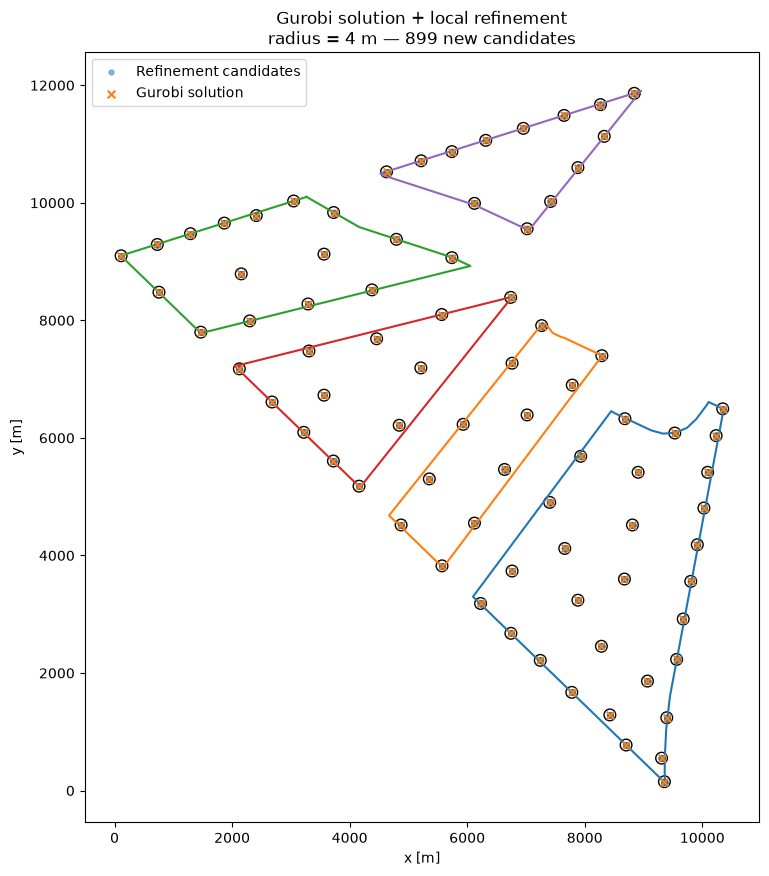

In [3]:
positions = load_layout_coordinates(STARTING_LAYOUT)

_, farm_area = get_farm_area()

candidate_locations, invalid_pairs = build_local_candidates(
    positions=positions,
    farm_area=farm_area,
    radius_m=RADIUS,
    step_m=GRID_RESOLUTION,
)

print(candidate_locations.shape)
print(invalid_pairs.shape)

plot_refinement(
    positions=positions,
    candidate_locations=candidate_locations,
    radius_m=RADIUS,
)

In [4]:
wake_loss_matrix, A0 = build_local_wake_loss_matrix_optimized(
    candidate_locations,
    output_path=WAKE_LOSS_PATH
)

# wake_loss = np.load(WAKE_LOSS_PATH)
# wake_loss_matrix = wake_loss["wake_loss_matrix"]
# A0 = wake_loss["A0"]

warm_start = get_warmstart(candidate_locations=candidate_locations, starting_layout=STARTING_LAYOUT)

Numero candidate locations: 980
Numero coppie totali: 479,710
Numero displacement unici: 123,655
Wake-loss data saved to: ../../results/precomputed/sqbm_qubo/wake_loss_sqbm_qubo_res_2m_rad_4.npz


In [5]:
Q, offset = build_qubo_from_wake_matrix_optimized(
    wake_loss_matrix,
    invalid_pairs,
    A0,
    n_turbines=81,
    lambda_cardinality=LAMBDA_CARDINALITY,
    lambda_spacing=LAMBDA_SPACING
)

In [6]:
solution, result = solve_wflo_sqbm(
    wake_loss_matrix,
    invalid_pairs,
    Q,
    host=SQBM_HOST,
    port=SQBM_PORT,
    timeout=TIMEOUT,
    algo=ALGO,
)

n = 980 variabili, SQBM+ @ 20.229.234.199:8000 (hdf5)
Campionamento completato in 62.4s  (server: 60.0s)
Turbine selezionate: 81
Pairwise wake loss: 848522.4579


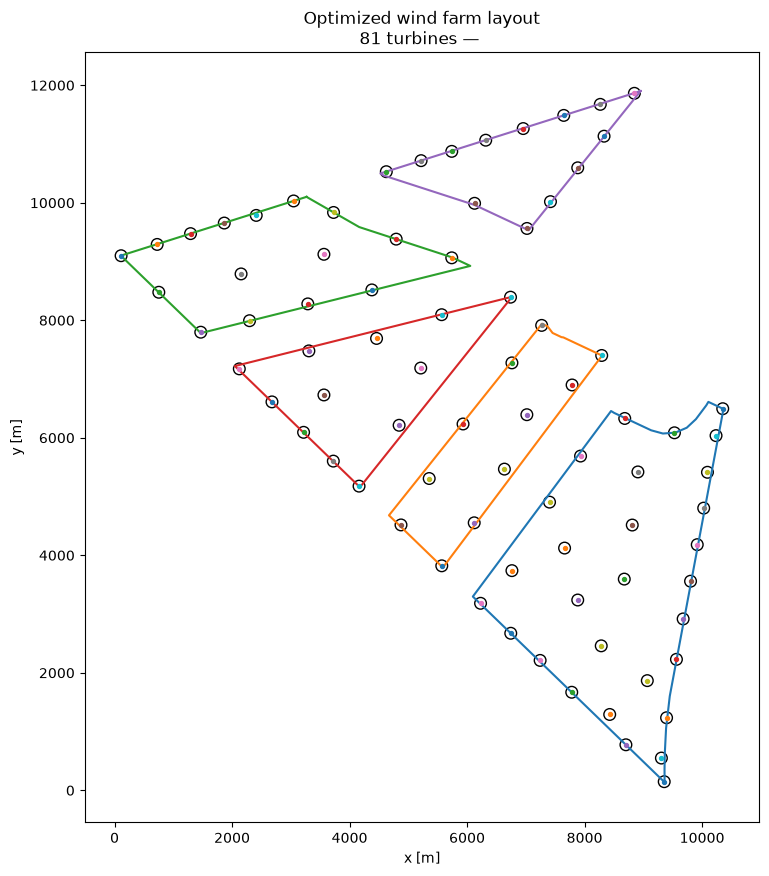

Layout saved to: /home/maicolnicolini/code/qubo-wind-farm-layout/notebooks/pipelines/../../results/layouts/sqbm_qubo/sqbm_qubo_local_2m_60s_warmstart.yaml
H_QUBO: 848522.4579483451
AEP: 2895.676962 GWh


PosixPath('/home/maicolnicolini/code/qubo-wind-farm-layout/notebooks/pipelines/../../results/layouts/sqbm_qubo/sqbm_qubo_local_2m_60s_warmstart.yaml')

In [7]:
selected_indices = np.flatnonzero(result.result)
selected_locations = candidate_locations[
    selected_indices
]

plot_selected_layout(selected_locations=selected_locations)

save_benchmark_layout(
    selected_locations=selected_locations,
    solver_name="ortools",
    output_dir=f"results/layouts/sqbm_qubo",
    filename=f"sqbm_qubo_local_{GRID_RESOLUTION}m_{TIMEOUT}s_warmstart.yaml",
    grid_resolution=GRID_RESOLUTION,
    time_limit_s=TIMEOUT,
    candidate_locations=candidate_locations,
    wake_loss_matrix=wake_loss_matrix,
)

In [8]:
df = layouts_folder_to_df(
    f"../../results/layouts/{SOLVER}"
)

df.sort_values(by="h_qubo", ascending=True)

,file,solver,grid_resolution,n_turbines,time_limit_s,h_qubo,aep_gwh
4,sqbm_qubo_local_2m_60s_warmstart.yaml,ortools,2,81,60.0,848522.457948,2895.676962
6,sqbm_qubo_local_4m_60s_warmstart.yaml,ortools,4,81,60.0,849039.628719,2895.295879
8,sqbm_qubo_local_8m_60s_warmstart.yaml,ortools,8,81,60.0,850112.667767,2894.522661
2,sqbm_qubo_local_16m_60s_warmstart.yaml,ortools,16,81,60.0,852669.738489,2892.861606
5,sqbm_qubo_local_32m_60s_warmstart.yaml,ortools,32,81,60.0,856005.034118,2890.508709
7,sqbm_qubo_local_64m_60s_warmstart.yaml,ortools,64,81,60.0,863642.087673,2884.518735
1,sqbm_qubo_local_128m_60s_warmstart.yaml,ortools,128,81,60.0,882612.281110,2869.853187
3,sqbm_qubo_local_256m_60s_warmstart.yaml,ortools,256,81,60.0,905309.462329,2851.189769
0,sqbm_256_0algo_60s.yaml,sqbm,256,81,NaN,NaN,2854.213811
